In [1]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="gpt-oss:120b-cloud")
print('Model is ready to use!')

c:\Users\ak60492\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model is ready to use!


In [2]:
# STEP-1: Define the state
from typing import TypedDict, Annotated
from langchain_core.messages import AnyMessage
from langgraph.graph.message import add_messages

class BlogState(TypedDict):
    topic: str
    introduction: str
    examples: str
    codes: str
    final_blog: str

print('Graph state is ready..')

Graph state is ready..


In [9]:
# Node definition

def planner(state: BlogState) -> BlogState:
    return state

def introduction(state: BlogState):
    topic = state['topic']
    return {
        "introduction": f"Introduction to {topic}"
    }

def example(state: BlogState):
    topic = state['topic']
    return {
        "examples": f"examples of {topic}"
    }

def codes(state: BlogState) -> BlogState:
    topic = state['topic']
    return {
        "codes": f"codes for {topic}"
    }

def merger(state: BlogState) -> BlogState:
    final_blog = (
f"{state['introduction']}\n\n"
        f"{state['examples']}\n\n"
        f"{state['topic']}\n\n"
        f"{state['codes']}"

    )
    state['final_blog'] = final_blog
    return state

print('All nodes ready"')

All nodes ready"


Graph is ready...


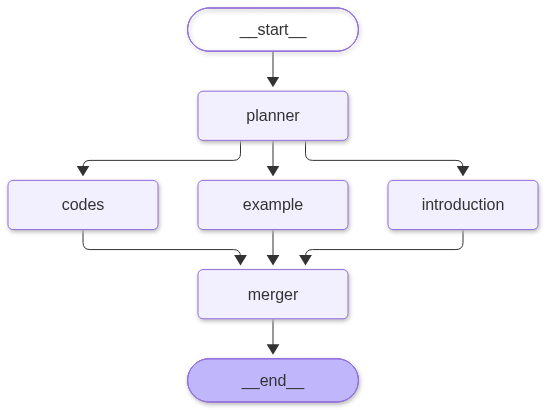

In [10]:
# STEP-3: Add edges and build the graph
from langgraph.graph import StateGraph, START, END

graph_builder = StateGraph(BlogState)

# Node registration
graph_builder.add_node("planner", planner)
graph_builder.add_node("introduction", introduction)
graph_builder.add_node("example", example)
graph_builder.add_node("codes", codes)
graph_builder.add_node("merger", merger)

# Add edges
graph_builder.add_edge(START, "planner")
graph_builder.add_edge("planner", "introduction")
graph_builder.add_edge("planner", "example")
graph_builder.add_edge("planner", "codes")

graph_builder.add_edge("introduction", "merger")
graph_builder.add_edge("example", "merger")
graph_builder.add_edge("codes", "merger")

graph_builder.add_edge("merger", END)

graph = graph_builder.compile()
print('Graph is ready...')
graph

In [11]:
response = graph.invoke({
    "topic": "Python"
})
response

{'topic': 'Python',
 'introduction': 'Introduction to Python',
 'examples': 'examples of Python',
 'codes': 'codes for Python',
 'final_blog': 'Introduction to Python\n\nexamples of Python\n\nPython\n\ncodes for Python'}